# Sprint 3 — Alertas determinísticos e fiéis

## Objetivo
Transformar leituras do motor W22 em episódios e alertas rastreáveis. O texto é montado com fatos calculados; o LLM apenas reescreve o template e toda resposta passa pelo verificador F1.

| Entregável | Seção |
|---|---:|
| Dados, mapeamento canônico e aviso sobre `data_variables.json` | 2 |
| Distribuição por severidade e limiares | 3 |
| Episódios e exemplos reais rastreáveis | 4 |
| Templates por severidade | 5 |
| Redação verificada por LLM | 6 |
| ROUGE e checklist de qualidade | 7 |
| Exportação JSON | 8 |


## 1. Configuração do ambiente

A execução é local. Antes de abrir o notebook, instale as dependências fixadas com `pip install -r requirements.txt`. A chave OpenRouter é lida do `.env` da raiz do repositório; não é necessário copiá-la para o ambiente da sessão. A célula mostra somente se a chave foi carregada.


In [1]:
from pathlib import Path
import os
import sys


def _is_repository_root(directory: Path) -> bool:
    return (
        (directory / "src" / "pln" / "config.py").is_file()
        and (directory / "requirements.txt").is_file()
    )


def _find_repository_root(start_directory: Path) -> Path | None:
    resolved_start = start_directory.resolve()
    candidates = (resolved_start, *resolved_start.parents)
    return next(
        (candidate for candidate in candidates if _is_repository_root(candidate)),
        None,
    )


repository_root = _find_repository_root(Path.cwd())
if repository_root is None:
    raise RuntimeError("N\u00e3o foi poss\u00edvel localizar a raiz do reposit\u00f3rio.")
if _find_repository_root(repository_root / "notebooks") != repository_root:
    raise RuntimeError("A raiz do reposit\u00f3rio n\u00e3o foi reconhecida a partir de notebooks/.")

repository_root_string = str(repository_root)
sys.path[:] = [
    repository_root_string,
    *(entry for entry in sys.path if entry != repository_root_string),
]
os.chdir(repository_root)

from src.pln.llm import load_openrouter_api_key

try:
    openrouter_key_available = bool(load_openrouter_api_key())
except RuntimeError:
    openrouter_key_available = False

print("chave carregada:", openrouter_key_available)


chave carregada: True


## 2. Dados e mapeamento canônico

O mapeamento abaixo combina as descrições e a magnitude observada. `data_variables.json` tem nomes e unidades inconsistentes com suas descrições e magnitudes; por isso, o catálogo registra a grandeza canônica e preserva a descrição original para auditoria.


In [2]:
import json
import pandas as pd

from src.pln.alertas import carregar_leituras
from src.pln.config import ALERT_TESTS_FILE
from src.pln.sensores import carregar_sensores

sensor_catalog = carregar_sensores()
readings = carregar_leituras()
alert_test_cases = json.loads(ALERT_TESTS_FILE.read_text(encoding="utf-8"))["casos"]
llm_test_results = []
real_redactions = {}

sensor_rows = [
    {
        "variable_id": sensor.variable_id,
        "grandeza": sensor.grandeza,
        "unidade": sensor.unidade,
        "limiares": sensor.limiares,
    }
    for sensor in sensor_catalog.values()
]
print(pd.DataFrame(sensor_rows).to_string(index=False))
print("Leituras carregadas:", len(readings))


                         variable_id                             grandeza unidade                                                   limiares
156b96a1-8899-463f-9311-c0cf754066ae                   Velocidade do eixo     rpm {'nominal': 1750.0, 'warning': 1800.0, 'critical': 1850.0}
3f809255-7687-4d25-92da-b8e134dcd01d     Vibração no mancal lado acoplado    mm/s          {'nominal': 1.5, 'warning': 2.8, 'critical': 4.5}
472e04da-4863-4f49-9cb8-1c9e164a4fa4                      Vibração global    mm/s                                                       None
8addd89b-70a5-4727-b2c0-bcea6b5c2d78           Corrente elétrica por fase       A    {'nominal': 125.0, 'warning': 140.0, 'critical': 160.0}
9c611f84-fb81-4db0-969e-7507d35e6761 Temperatura do enrolamento (estator)      °C      {'nominal': 75.0, 'warning': 90.0, 'critical': 110.0}
aa09b4cd-3b6b-4f56-8991-402ec305d26d      Temperatura interna das bobinas      °C                                                       None
Leituras carr

## 3. Severidade e limiares

A severidade é calculada por leitura. Valores abaixo do nominal são normais; nominal inicia a faixa leve, `warning` inicia a moderada e `critical` inicia a crítica. Sensores sem limiar ficam fora da contagem de alertas.


{'normal': 9918, 'leve': 12055, 'moderado': 3961, 'critico': 2818}


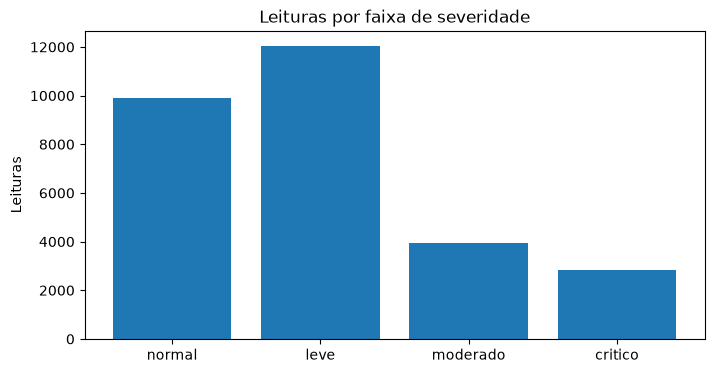

In [3]:
from collections import Counter
import matplotlib.pyplot as plt

from src.pln.alertas import classificar_severidade

severity_counts = Counter()
for reading in readings:
    sensor = sensor_catalog[reading["variable_id"]]
    if sensor.limiares is not None:
        severity = classificar_severidade(reading["value"], sensor.limiares)
        severity_counts[severity] += 1

severity_order = ["normal", "leve", "moderado", "critico"]
print({severity: severity_counts[severity] for severity in severity_order})
figure, axis = plt.subplots(figsize=(8, 4))
axis.bar(severity_order, [severity_counts[item] for item in severity_order])
axis.set_title("Leituras por faixa de severidade")
axis.set_ylabel("Leituras")
plt.show()


## 4. Episódios → alertas

Leituras consecutivas do mesmo sensor formam um episódio quando o intervalo é de até 60 minutos. O episódio recebe a maior severidade presente; episódios leves com menos de três leituras são descartados.


In [4]:
from collections import Counter

from src.pln.alertas import detectar_episodios, gerar_template

real_alerts = detectar_episodios(readings, sensor_catalog)
real_counts = Counter(alert.severidade for alert in real_alerts)
print({severity: real_counts[severity] for severity in ("leve", "moderado", "critico")})

real_examples = {}
for severity in ("leve", "moderado", "critico"):
    alert = next(item for item in real_alerts if item.severidade == severity)
    real_examples[severity] = alert
    print(f"\n{severity.upper()} | {alert.id} | leituras: {', '.join(alert.ids_leitura)}")
    print(gerar_template(alert))

synthetic_alerts = []
for case in alert_test_cases:
    alerts = detectar_episodios(case["leituras"], sensor_catalog)
    if case["descartar"]:
        assert alerts == []
        continue
    assert len(alerts) == 1
    assert alerts[0].severidade == case["severidade_esperada"]
    synthetic_alerts.append((case, alerts[0]))
assert len(synthetic_alerts) >= 9


{'leve': 495, 'moderado': 1788, 'critico': 2194}

LEVE | A-0003 | leituras: 86b1da61-efe3-47cd-bb61-dff83146e210, 0fb3fa63-3256-487b-8ef6-d3f9f049cdcc, 9062c9ac-2cca-4372-973b-ad4085cd6104
Alerta leve para o ativo Teste (Sorocaba); acompanhe a corrente elétrica por fase: pico 129,48 A; desvio +4,48 A acima do nominal 125,00 A. Em menos de um minuto, entre 05/05/2026 às 01:22:58 UTC e 05/05/2026 às 01:23:10 UTC. Monitore a corrente elétrica por fase nas próximas leituras.

MODERADO | A-0004 | leituras: bb66d48f-b0b0-493b-98eb-99d19050f1a3, 5743c2e1-50bc-4cba-b5bf-b02c47747aaa
Alerta moderado para o ativo Teste (Sorocaba); programe inspeção da velocidade do eixo: pico 1.821,75 rpm; desvio +71,75 rpm acima do nominal 1.750,00 rpm. Em menos de um minuto, entre 05/05/2026 às 01:22:58 UTC e 05/05/2026 às 01:23:04 UTC. Verifique a velocidade do eixo e programe inspeção.

CRITICO | A-0001 | leituras: bfea7713-7023-4faa-af1d-8642d718f468, 72ee814a-99df-4d86-b438-3e5ee087785c, 7d8caf2e-a6b3-41b7

## 5. Templates

Os templates usam os mesmos campos calculados e a ação padrão do sensor, com tom próprio para cada severidade.


In [5]:
import pandas as pd

template_rows = [
    {"severidade": severity, "texto": gerar_template(alert)}
    for severity, alert in real_examples.items()
]
print(pd.DataFrame(template_rows).to_string(index=False))


severidade                                                                                                                                                                                                                                                                                                              texto
      leve                     Alerta leve para o ativo Teste (Sorocaba); acompanhe a corrente elétrica por fase: pico 129,48 A; desvio +4,48 A acima do nominal 125,00 A. Em menos de um minuto, entre 05/05/2026 às 01:22:58 UTC e 05/05/2026 às 01:23:10 UTC. Monitore a corrente elétrica por fase nas próximas leituras.
  moderado              Alerta moderado para o ativo Teste (Sorocaba); programe inspeção da velocidade do eixo: pico 1.821,75 rpm; desvio +71,75 rpm acima do nominal 1.750,00 rpm. Em menos de um minuto, entre 05/05/2026 às 01:22:58 UTC e 05/05/2026 às 01:23:04 UTC. Verifique a velocidade do eixo e programe inspeção.
   critico Alerta crítico para o ativo Teste (

## 6. Redação por LLM sob verificador

O LLM recebe o template e só pode reescrever os fatos. Duas tentativas são permitidas; texto reprovado volta ao template. O cliente usa temperatura zero, cache local e o mesmo modelo nas retentativas.


In [6]:
from src.pln.alertas import gerar_template, verificar_texto
from src.pln.llm import create_openrouter_client, redigir_alerta_detalhado

sample_alert = synthetic_alerts[0][1]
template_sample = gerar_template(sample_alert)
assert verificar_texto(template_sample, sample_alert) == []
print("Exemplo aceito pelo verificador (template):", template_sample)
rejected_sample = template_sample + " Limite adicional de 100 °C."
assert verificar_texto(rejected_sample, sample_alert)
print("Exemplo rejeitado pelo verificador (número inventado):", rejected_sample)

api_failures = 0
if openrouter_key_available:
    llm_client = create_openrouter_client()
    for case, alert in synthetic_alerts:
        outcome = redigir_alerta_detalhado(alert, llm_client)
        api_failures += int(outcome.falha_api)
        llm_test_results.append((case, alert, outcome.texto, outcome))
    for alert in real_examples.values():
        outcome = redigir_alerta_detalhado(alert, llm_client)
        api_failures += int(outcome.falha_api)
        real_redactions[alert.id] = (outcome.texto, outcome.alerta)
    accepted = [item for item in llm_test_results if item[3].origem_texto == "llm"]
    rejected = [item for item in llm_test_results if item[3].rascunhos_rejeitados]
    acceptance_rate = len(accepted) / len(llm_test_results) if llm_test_results else 0
    print("Taxa de aceitação:", f"{acceptance_rate:.1%}")
    if accepted:
        print("origem_texto aceita:", accepted[0][3].origem_texto)
        print("Exemplo aceito:", accepted[0][2])
    if rejected:
        rejected_draft = rejected[0][3].rascunhos_rejeitados[-1]
        print("Candidato rejeitado pelo verificador:", rejected_draft.texto)
        print("Violações do candidato:")
        for violation in rejected_draft.violacoes:
            print(f"- {violation.codigo}: {violation.trecho or violation.mensagem}")
        if rejected[0][3].origem_texto == "template":
            print("Texto mantido (fallback para template):", rejected[0][2])
        else:
            print("Texto final após a nova tentativa:", rejected[0][2])
        print("origem_texto final:", rejected[0][3].origem_texto)
else:
    print("Chave ausente; a etapa LLM não foi chamada.")
print("Falhas de API:", api_failures)


Exemplo aceito pelo verificador (template): Alerta leve para o ativo Teste (Sorocaba); acompanhe a temperatura do enrolamento (estator): pico 82,00 °C; desvio +7,00 °C acima do nominal 75,00 °C. Na última hora, entre 01/06/2026 às 10:00 UTC e 01/06/2026 às 11:00 UTC. Monitore a temperatura do enrolamento nas próximas leituras.
Exemplo rejeitado pelo verificador (número inventado): Alerta leve para o ativo Teste (Sorocaba); acompanhe a temperatura do enrolamento (estator): pico 82,00 °C; desvio +7,00 °C acima do nominal 75,00 °C. Na última hora, entre 01/06/2026 às 10:00 UTC e 01/06/2026 às 11:00 UTC. Monitore a temperatura do enrolamento nas próximas leituras. Limite adicional de 100 °C.
Taxa de aceitação: 88.9%
origem_texto aceita: llm
Exemplo aceito: Alerta leve para o ativo Teste (Sorocaba); acompanhe a temperatura do enrolamento (estator): pico de 82,00 °C, acima do nominal de 75,00 °C, desvio de +7,00 °C. Na última hora, entre 01/06/2026 às 10:00 UTC e 01/06/2026 às 11:00 UTC. Mon

## 7. Avaliação: ROUGE e checklist

ROUGE-1, ROUGE-2 e ROUGE-L comparam os textos aos nove resumos manuais. O tokenizador próprio preserva letras acentuadas. BLEU é opcional e não foi incluído. Precisão, clareza (até 60 palavras) e utilidade são verificadas por alerta.


In [7]:
import re
from statistics import mean

import pandas as pd
from rouge_score.rouge_scorer import RougeScorer
from src.pln.alertas import verificar_clareza, verificar_texto

class AccentPreservingTokenizer:
    def tokenize(self, text):
        return re.findall(r"\w+", text.lower())


def calculate_rouge(pairs):
    scorer = RougeScorer(["rouge1", "rouge2", "rougeL"], tokenizer=AccentPreservingTokenizer())
    scores = {metric: [] for metric in ("rouge1", "rouge2", "rougeL")}
    for reference, generated in pairs:
        result = scorer.score(reference, generated)
        for metric in scores:
            scores[metric].append(result[metric].fmeasure)
    return {metric: mean(values) for metric, values in scores.items() if values}


def checklist_result(text, alert):
    sensor = sensor_catalog[alert.sensor_id]
    clarity = verificar_clareza(text, alert)
    return {
        "precisao": not verificar_texto(text, alert),
        "clareza": clarity,
        "utilidade": sensor.acoes_padrao[alert.severidade].casefold() in text.casefold(),
    }


template_pairs = [(case["resumo_referencia"], gerar_template(alert)) for case, alert in synthetic_alerts]
print("ROUGE template:", calculate_rouge(template_pairs))
if llm_test_results:
    llm_pairs = [(case["resumo_referencia"], text) for case, _, text, _ in llm_test_results]
    print("ROUGE LLM:", calculate_rouge(llm_pairs))
else:
    print("ROUGE LLM: indisponível sem execução da etapa LLM")

checklist_rows = []
for case, alert in synthetic_alerts:
    template_text = gerar_template(alert)
    checklist_rows.append({"caso": case["caso"], "origem": "template", **checklist_result(template_text, alert)})
for case, alert, text, result in llm_test_results:
    checklist_rows.append({"caso": case["caso"], "origem": result.origem_texto, **checklist_result(text, alert)})
template_checks = [row["precisao"] for row in checklist_rows if row["origem"] == "template"]
template_fidelity = sum(template_checks) / len(template_checks)
print("Fidelidade dos templates:", f"{template_fidelity:.1%}")
print(pd.DataFrame(checklist_rows).to_string(index=False))


ROUGE template: {'rouge1': 0.5856836506534485, 'rouge2': 0.3962236386420108, 'rougeL': 0.5426303850136852}
ROUGE LLM: {'rouge1': 0.5870404571542586, 'rouge2': 0.40096623419728267, 'rougeL': 0.4973052956537752}
Fidelidade dos templates: 100.0%
                   caso   origem  precisao  clareza  utilidade
       leve-temperatura template      True     True       True
          leve-corrente template      True     True       True
          leve-vibracao template      True     True       True
moderado-limite-warning template      True     True       True
      moderado-corrente template      True     True       True
      moderado-vibracao template      True     True       True
critico-limite-critical template      True     True       True
    critico-temperatura template      True     True       True
       critico-corrente template      True     True       True
       leve-temperatura      llm      True     True       True
          leve-corrente      llm      True     True       True
 

## 8. Exportação e conclusão

Exporta cada episódio real com os fatos calculados, os IDs de leitura e o texto cuja origem foi registrada. O resumo final inclui contagens por severidade.


In [8]:
from dataclasses import asdict
import json

from src.pln.config import ALERTS_OUTPUT_FILE

ALERTS_OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)
exported_alerts = []
for alert in real_alerts:
    text, result = real_redactions.get(alert.id, (gerar_template(alert), alert))
    record = asdict(result)
    record["inicio"] = result.inicio.isoformat()
    record["fim"] = result.fim.isoformat()
    record["ids_leitura"] = list(result.ids_leitura)
    record["texto"] = text
    exported_alerts.append(record)

ALERTS_OUTPUT_FILE.write_text(
    json.dumps(exported_alerts, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)
print("Alertas exportados:", len(exported_alerts))
print("Contagem por severidade:", {severity: real_counts[severity] for severity in ("leve", "moderado", "critico")})
print("Arquivo:", ALERTS_OUTPUT_FILE)


Alertas exportados: 4477
Contagem por severidade: {'leve': 495, 'moderado': 1788, 'critico': 2194}
Arquivo: C:\Users\Igor\Desktop\Sarak\Fiap\CP - Sprint - GS\2º Ano\Sprints\Sprint 4\data\saida\alertas.json


## 9. Conjunto de eventos rotulados

O conjunto local contém 60 eventos, distribuídos entre cinco categorias e os splits dev e teste. A tabela confere a contagem por classe e split; em seguida, um exemplo de cada classe permite revisar os rótulos sem chamar serviços externos.


In [9]:
import pandas as pd

from src.pln.classificacao import carregar_eventos
from src.pln.config import CATEGORIAS_EVENTO

eventos_rotulados = carregar_eventos()
resumo_eventos = pd.DataFrame(
    [
        {
            "categoria": categoria,
            "total": sum(evento["rotulo"] == categoria for evento in eventos_rotulados),
            "dev": sum(
                evento["rotulo"] == categoria and evento["split"] == "dev"
                for evento in eventos_rotulados
            ),
            "teste": sum(
                evento["rotulo"] == categoria and evento["split"] == "teste"
                for evento in eventos_rotulados
            ),
        }
        for categoria in CATEGORIAS_EVENTO
    ]
)
print(f"Total de eventos: {len(eventos_rotulados)}")
print(resumo_eventos.to_string(index=False))

exemplos_eventos = [
    next(evento for evento in eventos_rotulados if evento["rotulo"] == categoria)
    for categoria in CATEGORIAS_EVENTO
]
print(
    pd.DataFrame(
        [
            {
                "categoria": evento["rotulo"],
                "id": evento["id"],
                "split": evento["split"],
                "origem": evento["origem"],
                "texto": evento["texto"],
            }
            for evento in exemplos_eventos
        ]
    ).to_string(index=False)
)


Total de eventos: 60
            categoria  total  dev  teste
 manutenção corretiva     12    2     10
manutenção preventiva     12    2     10
    anomalia elétrica     12    2     10
    anomalia mecânica     12    2     10
      operação normal     12    2     10
            categoria    id split    origem                                                                               texto
 manutenção corretiva E-001   dev sintetico OS corretiva: após interrupção, rolamento foi trocado; serviço registrado no turno.
manutenção preventiva E-013   dev sintetico          Plano de inspeção programada incluiu lubrificação antes da próxima parada.
    anomalia elétrica E-025   dev sintetico  Corrente por fase variou acima da referência; painel registrou alarme no terminal.
    anomalia mecânica E-037   dev sintetico                    Vibração no mancal subiu junto de ruído metálico em baixa carga.
      operação normal E-049   dev sintetico               Operação estável, carga regular e l

## 10. Classificação: linha de base e zero-shot

O léxico da linha de base e o prompt com as definições das cinco categorias são definidos a partir do split dev. A avaliação final compara os dois métodos uma vez nos 50 eventos do split teste, mostra F1 por categoria, métricas macro e ponderadas, matrizes de confusão e erros do zero-shot. Execute esta seção depois da revisão humana dos rótulos e com OPENROUTER_API_KEY disponível.


In [10]:
if not openrouter_key_available:
    raise RuntimeError(
        "Defina OPENROUTER_API_KEY no ambiente antes de executar a avaliação zero-shot."
    )

import pandas as pd

from src.pln.classificacao import avaliar_split_teste, carregar_eventos
from src.pln.config import CATEGORIAS_EVENTO
from src.pln.llm import create_openrouter_client

eventos_para_avaliacao = carregar_eventos()
resultado_classificacao = avaliar_split_teste(
    eventos_para_avaliacao,
    create_openrouter_client(),
)
print(f"Suporte do split teste: {resultado_classificacao['suporte_teste']}")

linhas_metricas = []
for nome_modelo, metricas in (
    ("Linha de base", resultado_classificacao["linha_de_base"]),
    ("Zero-shot", resultado_classificacao["zero_shot"]),
):
    for categoria, valores in metricas["por_categoria"].items():
        linhas_metricas.append(
            {
                "modelo": nome_modelo,
                "categoria": categoria,
                "precisão": valores["precision"],
                "revocação": valores["recall"],
                "F1": valores["f1-score"],
                "suporte": valores["support"],
            }
        )
    for nome_media, chave in (("Macro", "macro"), ("Ponderada", "ponderado")):
        valores = metricas[chave]
        linhas_metricas.append(
            {
                "modelo": nome_modelo,
                "categoria": nome_media,
                "precisão": valores["precision"],
                "revocação": valores["recall"],
                "F1": valores["f1-score"],
                "suporte": valores["support"],
            }
        )
print(pd.DataFrame(linhas_metricas).to_string(index=False))

for nome_modelo, metricas in (
    ("Linha de base", resultado_classificacao["linha_de_base"]),
    ("Zero-shot", resultado_classificacao["zero_shot"]),
):
    matriz = pd.DataFrame(
        metricas["matriz_confusao"],
        index=CATEGORIAS_EVENTO,
        columns=metricas["rotulos_matriz"],
    )
    print(f"\nMatriz de confusão — {nome_modelo}")
    print(matriz.to_string())

print("\nErros do zero-shot")
print(
    pd.DataFrame(
        resultado_classificacao["zero_shot"]["erros"],
        columns=["id", "texto", "esperado", "obtido"],
    ).to_string(index=False)
)


Suporte do split teste: 50
       modelo             categoria  precisão  revocação       F1  suporte
Linha de base  manutenção corretiva  0.500000       0.10 0.166667     10.0
Linha de base manutenção preventiva  1.000000       0.10 0.181818     10.0
Linha de base     anomalia elétrica  0.000000       0.00 0.000000     10.0
Linha de base     anomalia mecânica  0.000000       0.00 0.000000     10.0
Linha de base       operação normal  0.000000       0.00 0.000000     10.0
Linha de base                 Macro  0.300000       0.04 0.069697     50.0
Linha de base             Ponderada  0.300000       0.04 0.069697     50.0
    Zero-shot  manutenção corretiva  1.000000       0.70 0.823529     10.0
    Zero-shot manutenção preventiva  1.000000       0.60 0.750000     10.0
    Zero-shot     anomalia elétrica  0.833333       1.00 0.909091     10.0
    Zero-shot     anomalia mecânica  0.588235       1.00 0.740741     10.0
    Zero-shot       operação normal  0.875000       0.70 0.777778     10.

## 11. Relatório diário

O relatório diário usa o dia mais recente do CSV que tenha leituras e ao menos um alerta. A data 2026-08-23 tem 18 leituras, mas nenhum alerta; por isso, a janela diária selecionada é 2026-08-22. Cada frase gerada inclui referências rastreáveis.


In [11]:
import json

from src.pln.alertas import carregar_leituras
from src.pln.config import ALERTS_OUTPUT_FILE, PERIODO_DIARIO
from src.pln.relatorio import gerar_relatorio

alertas_reais = json.loads(ALERTS_OUTPUT_FILE.read_text(encoding="utf-8"))
leituras_relatorio = carregar_leituras()
relatorio_diario = gerar_relatorio(
    alertas_reais,
    PERIODO_DIARIO,
    leituras_relatorio,
)
print(relatorio_diario)


Resumo
Velocidade do eixo: 1 leve, 9 moderados, 7 críticos no período [ref: período | sensor 156b96a1-8899-463f-9311-c0cf754066ae]
Vibração no mancal lado acoplado: 4 leves, 7 moderados, 4 críticos no período [ref: período | sensor 3f809255-7687-4d25-92da-b8e134dcd01d]
Vibração global: 0 leves, 0 moderados, 0 críticos no período [ref: período | sensor 472e04da-4863-4f49-9cb8-1c9e164a4fa4]
Corrente elétrica por fase: 3 leves, 3 moderados, 5 críticos no período [ref: período | sensor 8addd89b-70a5-4727-b2c0-bcea6b5c2d78]
Temperatura do enrolamento (estator): 1 leve, 4 moderados, 6 críticos no período [ref: período | sensor 9c611f84-fb81-4db0-969e-7507d35e6761]
Temperatura interna das bobinas: 0 leves, 0 moderados, 0 críticos no período [ref: período | sensor aa09b4cd-3b6b-4f56-8991-402ec305d26d]

Alertas emitidos
Alerta de severidade crítica para Vibração no mancal lado acoplado: pico 4,89 mm/s [ref: A-4425 | ids: d34891be-7c80-4b52-ab6b-0c9b3ac5dd2b,dbae9482-c8bc-4998-8495-9d7eedfa8860]

## 12. Relatório semanal

A janela semanal cobre sete dias e termina no último dia com leituras, 2026-08-23. O texto é determinístico e todas as frases carregam referências aos alertas ou às leituras que sustentam os dados agregados.


In [12]:
from src.pln.config import PERIODO_SEMANAL
from src.pln.relatorio import gerar_relatorio

relatorio_semanal = gerar_relatorio(
    alertas_reais,
    PERIODO_SEMANAL,
    leituras_relatorio,
)
print(relatorio_semanal)


Resumo
Velocidade do eixo: 1 leve, 9 moderados, 7 críticos no período [ref: período | sensor 156b96a1-8899-463f-9311-c0cf754066ae]
Vibração no mancal lado acoplado: 4 leves, 7 moderados, 4 críticos no período [ref: período | sensor 3f809255-7687-4d25-92da-b8e134dcd01d]
Vibração global: 0 leves, 0 moderados, 0 críticos no período [ref: período | sensor 472e04da-4863-4f49-9cb8-1c9e164a4fa4]
Corrente elétrica por fase: 3 leves, 3 moderados, 5 críticos no período [ref: período | sensor 8addd89b-70a5-4727-b2c0-bcea6b5c2d78]
Temperatura do enrolamento (estator): 1 leve, 4 moderados, 6 críticos no período [ref: período | sensor 9c611f84-fb81-4db0-969e-7507d35e6761]
Temperatura interna das bobinas: 0 leves, 0 moderados, 0 críticos no período [ref: período | sensor aa09b4cd-3b6b-4f56-8991-402ec305d26d]

Alertas emitidos
Alerta de severidade crítica para Vibração no mancal lado acoplado: pico 4,89 mm/s [ref: A-4425 | ids: d34891be-7c80-4b52-ab6b-0c9b3ac5dd2b,dbae9482-c8bc-4998-8495-9d7eedfa8860]

## 13. Avaliação dos relatórios: ROUGE e checklist

ROUGE-1, ROUGE-2 e ROUGE-L comparam cada texto determinístico à referência manual do mesmo período. O checklist verifica precisão, clareza, utilidade e rastreabilidade, além de informar violações e a proporção de frases rastreáveis.


In [13]:
import json

import pandas as pd

from src.pln.config import (
    PERIODO_DIARIO,
    PERIODO_SEMANAL,
    REPORT_REFERENCE_FILE,
    SECOES_RELATORIO,
)
from src.pln.relatorio import ReportEvaluationContext, avaliar_relatorio

referencias_relatorio = json.loads(
    REPORT_REFERENCE_FILE.read_text(encoding="utf-8")
)

def texto_referencia(secoes):
    return "\n".join(
        f"{secao}\n{secoes[secao]}" for secao in SECOES_RELATORIO
    )

avaliacoes_relatorios = {}
for periodo, texto in (
    (PERIODO_DIARIO, relatorio_diario),
    (PERIODO_SEMANAL, relatorio_semanal),
):
    contexto = ReportEvaluationContext(
        alertas=alertas_reais,
        leituras=leituras_relatorio,
        periodo=periodo,
    )
    avaliacoes_relatorios[periodo] = avaliar_relatorio(
        texto,
        texto_referencia(referencias_relatorio[periodo]),
        contexto,
    )

linhas_avaliacao = []
for periodo, avaliacao in avaliacoes_relatorios.items():
    linhas_avaliacao.append(
        {
            "periodo": periodo,
            **avaliacao["rouge"],
            **avaliacao["checklist"],
            "frases_rastreaveis_pct": avaliacao["frases_rastreaveis_pct"],
            "violacoes": len(avaliacao["violacoes"]),
        }
    )
print(pd.DataFrame(linhas_avaliacao).to_string(index=False))


periodo   rouge1   rouge2   rougeL  precisao  clareza  utilidade  rastreabilidade  frases_rastreaveis_pct  violacoes
 diario 0.449275 0.285714 0.350242      True     True       True             True                   100.0          0
semanal 0.452830 0.297872 0.367925      True     True       True             True                   100.0          0


## 14. Exportação e conclusão

Após a avaliação zero-shot e a geração dos dois relatórios, esta seção exporta os resultados para data/saida/classificacao.json, data/saida/relatorio_diario.json e data/saida/relatorio_semanal.json. A execução desta célula pertence à Fase B.


In [14]:
import json

from src.pln.config import (
    CLASSIFICATION_OUTPUT_FILE,
    DAILY_REPORT_OUTPUT_FILE,
    MODELO_CLASSIFICADOR,
    PERIODO_DIARIO,
    PERIODO_SEMANAL,
    WEEKLY_REPORT_OUTPUT_FILE,
)

def exportar_json(destino, conteudo):
    destino.parent.mkdir(parents=True, exist_ok=True)
    destino.write_text(
        json.dumps(conteudo, ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )

exportar_json(
    CLASSIFICATION_OUTPUT_FILE,
    {
        "modelo": MODELO_CLASSIFICADOR,
        **resultado_classificacao,
    },
)
exportar_json(
    DAILY_REPORT_OUTPUT_FILE,
    {
        "periodo": PERIODO_DIARIO,
        "texto": relatorio_diario,
        "avaliacao": avaliacoes_relatorios[PERIODO_DIARIO],
    },
)
exportar_json(
    WEEKLY_REPORT_OUTPUT_FILE,
    {
        "periodo": PERIODO_SEMANAL,
        "texto": relatorio_semanal,
        "avaliacao": avaliacoes_relatorios[PERIODO_SEMANAL],
    },
)

print(f"Eventos no conjunto: {len(eventos_para_avaliacao)}")
print(
    "F1 macro — linha de base: "
    f"{resultado_classificacao['linha_de_base']['macro']['f1-score']:.4f}"
)
print(
    "F1 macro — zero-shot: "
    f"{resultado_classificacao['zero_shot']['macro']['f1-score']:.4f}"
)
for caminho in (
    CLASSIFICATION_OUTPUT_FILE,
    DAILY_REPORT_OUTPUT_FILE,
    WEEKLY_REPORT_OUTPUT_FILE,
):
    print(f"Exportado: {caminho}")


Eventos no conjunto: 60
F1 macro — linha de base: 0.0697
F1 macro — zero-shot: 0.8002
Exportado: C:\Users\Igor\Desktop\Sarak\Fiap\CP - Sprint - GS\2º Ano\Sprints\Sprint 4\data\saida\classificacao.json
Exportado: C:\Users\Igor\Desktop\Sarak\Fiap\CP - Sprint - GS\2º Ano\Sprints\Sprint 4\data\saida\relatorio_diario.json
Exportado: C:\Users\Igor\Desktop\Sarak\Fiap\CP - Sprint - GS\2º Ano\Sprints\Sprint 4\data\saida\relatorio_semanal.json
